# Chicago Weather Trends, 2015–2024

**An exploratory analysis of ten years of daily weather in Chicago, IL.**

| | |
|---|---|
| **Data** | Open-Meteo Historical Weather API (ERA5 reanalysis), daily, 1 Jan 2015 – 31 Dec 2024 |
| **Location** | Chicago Loop (41.88° N, 87.63° W) → nearest grid cell 41.86° N, 87.65° W, 241 m |
| **Tools** | Python · Requests · Pandas · NumPy · SciPy · Matplotlib · Seaborn · Jupyter |

### Questions
1. **Temperature trend:** Did Chicago get warmer across the decade, and is the change statistically meaningful?
2. **Seasonality:** What does the annual cycle look like, and do all seasons change in the same way?
3. **Extremes:** How often do hot, freezing and anomalous days occur, and is that changing?
4. **Precipitation:** How are rain and snow distributed through the year, and what do heavy-rain days look like?
5. **Relationships:** How do temperature, sunshine, cloud, humidity, pressure and precipitation relate?

> **Pipeline:** `src/fetch_data.py` (API → `data/raw/`) → `src/prepare_data.py` (validation, cleaning, feature engineering → `data/processed/`) → this notebook (analysis & figures → `figures/`).

## 1. Setup

In [1]:
import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed" / "chicago_daily_clean.csv"
QUALITY = ROOT / "data" / "processed" / "data_quality_report.json"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
if not DATA.exists():
    raise FileNotFoundError("Run `python src/fetch_data.py` and `python src/prepare_data.py` first.")

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

In [2]:
# ---- Visual system: one palette, recessive chrome, one y-axis per chart ----
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"   # blue = cold / below, orange-red = warm / above
NEUTRAL = "#f0efec"
DIVERGING = LinearSegmentedColormap.from_list(
    "cool_warm", ["#104281", "#3987e5", "#b7d3f6", NEUTRAL, "#f4b5b4", "#e34948", "#9e2a2a"])
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10.5,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False, "legend.labelcolor": INK_2, "lines.linewidth": 2,
})


def titled(ax, title, subtitle=None):
    """Left-aligned headline title with an optional secondary-ink subtitle under it."""
    ax.set_title(title, pad=30 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=INK_2, fontsize=10, va="bottom")


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


def trend(series: pd.Series) -> dict:
    """OLS slope plus a non-parametric Mann-Kendall-style check (Kendall's tau vs. time)."""
    x, y = series.index.to_numpy(dtype=float), series.to_numpy(dtype=float)
    lr, tau = stats.linregress(x, y), stats.kendalltau(x, y)
    return {"slope_per_year": lr.slope, "slope_per_decade": lr.slope * 10, "r2": lr.rvalue ** 2,
            "p_ols": lr.pvalue, "kendall_tau": tau.statistic, "p_kendall": tau.pvalue,
            "intercept": lr.intercept}

## 2. Load & check the data

In [3]:
df = pd.read_csv(DATA, parse_dates=["date"])
quality = json.loads(QUALITY.read_text())
print(f"{len(df):,} days  |  {df['date'].min():%d %b %Y} → {df['date'].max():%d %b %Y}  |  {df.shape[1]} columns")
df.head(3)

3,653 days  |  01 Jan 2015 → 31 Dec 2024  |  32 columns


,date,tmax_c,tmin_c,tmean_c,feels_like_c,precip_mm,rain_mm,snow_cm,precip_hours,wind_max_kmh,...,wind_chill_gap_c,is_wet_day,is_snow_day,is_hot_day,is_freezing_day,is_ice_day,is_heavy_precip_day,tmean_climatology_c,tmean_anomaly_c,is_temp_outlier
0,2015-01-01,-1.00,-7.20,-4.20,-11.40,0.00,0.00,0.00,0.00,30.80,...,7.20,False,False,False,True,True,False,-1.72,-2.48,False
1,2015-01-02,-0.10,-4.70,-2.00,-6.20,0.00,0.00,0.00,0.00,14.10,...,4.20,False,False,False,True,True,False,-1.80,-0.20,False
2,2015-01-03,0.80,-0.90,0.10,-3.50,19.80,13.40,4.48,17.00,16.30,...,3.60,True,True,False,True,False,False,-1.82,1.92,False


`prepare_data.py` runs integrity checks before anything is analysed. Out-of-bounds values would be set to missing and short gaps (≤ 3 days) interpolated for continuous variables, while precipitation is never interpolated, since filling it would invent rain. For this extract **every check passed**, so no values were changed:

In [4]:
checks = {
    "Duplicate dates": quality["duplicate_dates"],
    "Missing calendar days": quality["missing_dates"],
    "Missing values (all columns)": sum(quality["missing_values"].values()),
    "Values outside physical bounds": sum(quality["out_of_bounds"].values()),
    "Daily min > daily max": quality["tmin_gt_tmax"],
    "Daily mean outside [min, max]": quality["tmean_outside_min_max"],
    "Rain > total precipitation": quality["rain_gt_precip"],
    "Gusts < sustained wind": quality["gust_lt_wind"],
    "Values imputed": quality["values_imputed"],
}
pd.Series(checks, name="Rows affected").to_frame()

,Rows affected
Duplicate dates,0
Missing calendar days,0
Missing values (all columns),0
Values outside physical bounds,0
Daily min > daily max,0
"Daily mean outside [min, max]",0
Rain > total precipitation,0
Gusts < sustained wind,0
Values imputed,0


In [5]:
summary_cols = {"tmax_c": "Max temp (°C)", "tmin_c": "Min temp (°C)", "tmean_c": "Mean temp (°C)",
                "precip_mm": "Precipitation (mm)", "snow_cm": "Snowfall (cm)", "wind_max_kmh": "Max wind (km/h)",
                "humidity_pct": "Humidity (%)", "cloud_pct": "Cloud cover (%)", "solar_mj_m2": "Solar (MJ/m²)",
                "pressure_hpa": "Pressure (hPa)"}
df[list(summary_cols)].describe().T.rename(index=summary_cols)[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
Max temp (°C),14.29,10.90,-22.80,14.60,37.40
Min temp (°C),6.48,10.41,-32.50,6.30,25.50
Mean temp (°C),10.43,10.46,-28.30,10.50,30.90
Precipitation (mm),3.19,7.10,0.00,0.10,137.80
Snowfall (cm),0.20,0.98,0.00,0.00,18.69
Max wind (km/h),24.87,7.77,7.60,23.90,57.40
Humidity (%),74.35,11.24,33.00,75.00,99.00
Cloud cover (%),60.67,30.12,0.00,65.00,100.00
Solar (MJ/m²),14.68,7.80,0.47,14.06,31.04
Pressure (hPa),"1,017.04",7.10,991.90,"1,016.60","1,044.70"


**Engineered features** (added in `prepare_data.py`): calendar fields, meteorological season (Dec–Feb = winter; December is assigned to the *following* winter), diurnal temperature range, threshold flags (wet day ≥ 1 mm, heavy day ≥ the 95th percentile of wet days, hot day ≥ 32.2 °C / 90 °F, freezing day = min < 0 °C, ice day = max < 0 °C), and a **daily anomaly**: each day's mean temperature minus a 31-day-smoothed day-of-year average for the decade.

## 3. Q1: Is Chicago getting warmer?

In [6]:
annual = df.groupby("year").agg(
    mean_temp_c=("tmean_c", "mean"), hottest_c=("tmax_c", "max"), coldest_c=("tmin_c", "min"),
    precip_mm=("precip_mm", "sum"), snow_cm=("snow_cm", "sum"), wet_days=("is_wet_day", "sum"),
    heavy_days=("is_heavy_precip_day", "sum"), hot_days=("is_hot_day", "sum"),
    freezing_days=("is_freezing_day", "sum"), ice_days=("is_ice_day", "sum"))
annual.style.format("{:.1f}", subset=["mean_temp_c", "hottest_c", "coldest_c", "precip_mm", "snow_cm"]) \
    .format("{:.0f}", subset=["wet_days", "heavy_days", "hot_days", "freezing_days", "ice_days"])

,mean_temp_c,hottest_c,coldest_c,precip_mm,snow_cm,wet_days,heavy_days,hot_days,freezing_days,ice_days
year,,,,,,,,,,
2015,9.2,29.5,-22.8,1041.8,81.9,123,6,0,98,58
2016,10.5,30.9,-19.7,904.1,66.6,119,4,0,99,45
2017,10.8,33.6,-19.2,1297.2,27.4,127,9,2,96,33
2018,9.7,34.5,-21.8,1392.9,100.0,157,9,8,137,35
2019,9.4,34.0,-32.5,1394.7,97.7,154,8,5,128,41
2020,10.7,35.4,-22.1,1089.5,66.8,134,6,9,109,23
2021,11.2,33.6,-21.9,1142.8,93.9,134,6,12,113,31
2022,10.0,37.4,-24.5,1117.7,74.1,119,8,9,115,49
2023,11.0,37.1,-19.5,1245.5,49.8,125,7,6,90,14


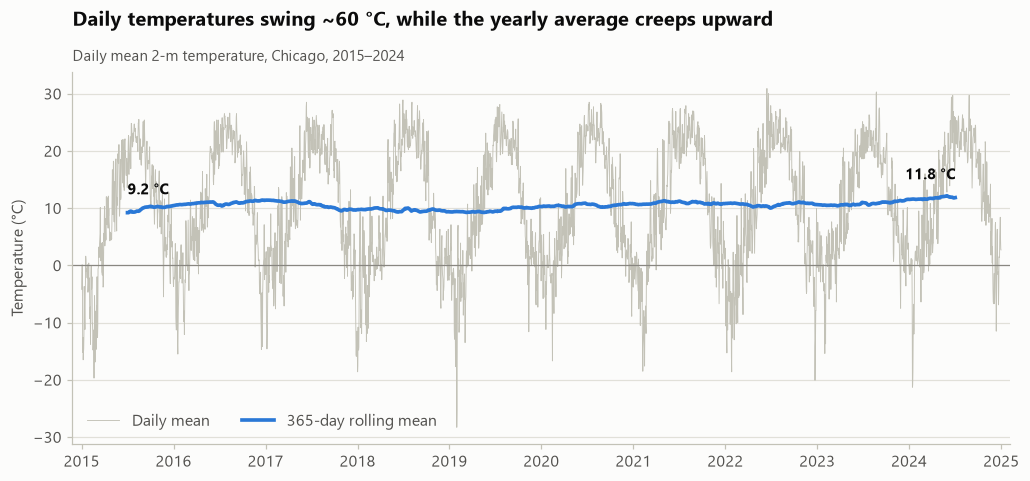

In [7]:
roll = df.set_index("date")["tmean_c"].rolling(365, center=True).mean()

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(df["date"], df["tmean_c"], color=AXIS, lw=0.6, label="Daily mean")
ax.plot(roll.index, roll, color=BLUE, lw=2.4, label="365-day rolling mean")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_ylabel("Temperature (°C)")
ax.margins(x=0.01)
ax.legend(loc="lower left", ncol=2)
first, last = roll.dropna().iloc[0], roll.dropna().iloc[-1]
ax.annotate(f"{first:.1f} °C", (roll.dropna().index[0], first), xytext=(0, 12), textcoords="offset points",
            color=INK, fontsize=10, ha="left", fontweight="bold")
ax.annotate(f"{last:.1f} °C", (roll.dropna().index[-1], last), xytext=(0, 12), textcoords="offset points",
            color=INK, fontsize=10, ha="right", fontweight="bold")
titled(ax, "Daily temperatures swing ~60 °C, while the yearly average creeps upward",
       "Daily mean 2-m temperature, Chicago, 2015–2024")
save(fig, "01_daily_temperature_rolling_mean")

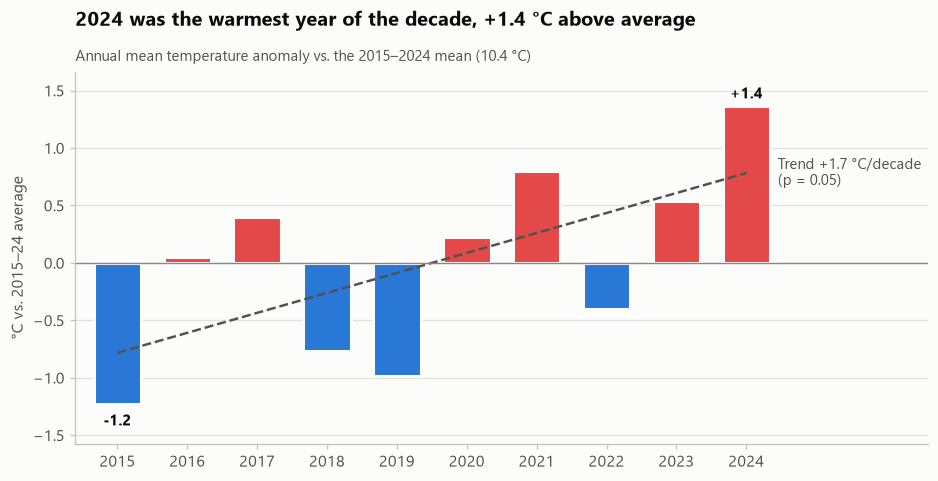

In [8]:
baseline = annual["mean_temp_c"].mean()
anom = annual["mean_temp_c"] - baseline
t_mean = trend(annual["mean_temp_c"])
warmest = anom.idxmax()

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.bar(anom.index, anom, color=[RED if v > 0 else BLUE for v in anom], width=0.68, edgecolor=SURFACE, linewidth=2)
fit = pd.Series(t_mean["intercept"] + t_mean["slope_per_year"] * anom.index.to_numpy() - baseline, index=anom.index)
ax.plot(anom.index, fit, color=INK_2, lw=1.6, ls="--")
ax.text(anom.index[-1] + 0.45, fit.iloc[-1], f"Trend {t_mean['slope_per_decade']:+.1f} °C/decade\n(p = {t_mean['p_ols']:.2f})",
        color=INK_2, fontsize=9.5, va="center")
for yr in [anom.idxmin(), warmest]:
    v = anom[yr]
    ax.annotate(f"{v:+.1f}", (yr, v), xytext=(0, 5 if v > 0 else -14), textcoords="offset points",
                ha="center", color=INK, fontsize=10, fontweight="bold")
ax.axhline(0, color=MUTED, lw=0.9)
ax.set_xticks(anom.index)
ax.set_ylabel("°C vs. 2015–24 average")
ax.set_xlim(2014.4, 2026.6)
ax.set_ylim(anom.min() - 0.35, anom.max() + 0.3)
titled(ax, f"{warmest} was the warmest year of the decade, {anom[warmest]:+.1f} °C above average",
       f"Annual mean temperature anomaly vs. the 2015–2024 mean ({baseline:.1f} °C)")
save(fig, "02_annual_temperature_anomaly")

In [9]:
trend_vars = {"mean_temp_c": "Annual mean temp (°C)", "hottest_c": "Hottest day (°C)",
              "coldest_c": "Coldest night (°C)", "hot_days": "Hot days ≥ 32.2 °C",
              "freezing_days": "Freezing days (min < 0 °C)", "ice_days": "Ice days (max < 0 °C)",
              "precip_mm": "Total precipitation (mm)", "wet_days": "Wet days ≥ 1 mm",
              "snow_cm": "Snowfall (cm)"}
trends = pd.DataFrame({label: trend(annual[col]) for col, label in trend_vars.items()}).T
trends["significant (p<0.05)"] = np.where((trends["p_ols"] < 0.05) & (trends["p_kendall"] < 0.05), "yes", "no")
trends[["slope_per_decade", "r2", "p_ols", "p_kendall", "significant (p<0.05)"]]

,slope_per_decade,r2,p_ols,p_kendall,significant (p<0.05)
Annual mean temp (°C),1.74,0.40,0.05,0.05,yes
Hottest day (°C),7.36,0.77,0.00,0.01,yes
Coldest night (°C),-2.11,0.03,0.65,0.48,no
Hot days ≥ 32.2 °C,12.18,0.67,0.00,0.01,yes
Freezing days (min < 0 °C),-8.48,0.03,0.66,0.60,no
Ice days (max < 0 °C),-29.76,0.45,0.03,0.05,yes
Total precipitation (mm),20.42,0.00,0.92,1.00,no
Wet days ≥ 1 mm,-6.91,0.02,0.68,0.65,no
Snowfall (cm),-8.06,0.01,0.77,0.48,no


**Reading the trend.** The annual mean rises about **1.7 °C per decade** (both tests give p ≈ 0.05), and 2024 is the warmest year. The clearest signal is the **number of hot days**, which climbs about 12 per decade (p < 0.01, R² ≈ 0.67): from zero in 2015–16 to 12 in both 2021 and 2024.

⚠️ *Ten years is a short window for climate claims.* One cold year (2015 or 2019) or warm year (2024) moves the slope noticeably. Long-term records for the Midwest show warming nearer 0.2–0.3 °C per decade, so the decade-scale slope here combines that background warming with year-to-year variability. Treat it as *consistent with warming*, not as a measured warming rate.

## 4. Q2: Seasonal patterns

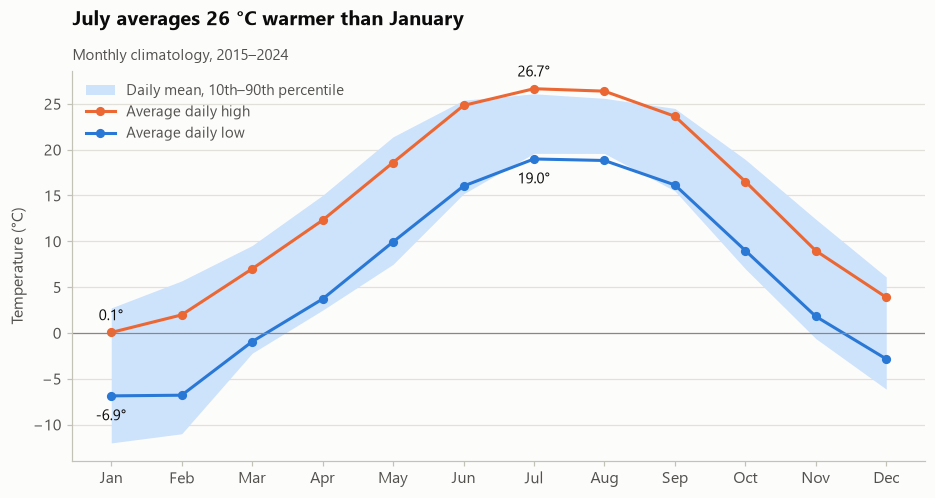

In [10]:
clim = df.groupby("month").agg(high=("tmax_c", "mean"), low=("tmin_c", "mean"), mean=("tmean_c", "mean"),
                               p10=("tmean_c", lambda s: s.quantile(0.10)),
                               p90=("tmean_c", lambda s: s.quantile(0.90)))
x = np.arange(12)
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.fill_between(x, clim["p10"], clim["p90"], color="#cde2fb", lw=0, label="Daily mean, 10th–90th percentile")
ax.plot(x, clim["high"], color=ORANGE, marker="o", ms=5, label="Average daily high")
ax.plot(x, clim["low"], color=BLUE, marker="o", ms=5, label="Average daily low")
for series, color, dy in [(clim["high"], ORANGE, 8), (clim["low"], BLUE, -16)]:
    for m in (0, 6):
        ax.annotate(f"{series.iloc[m]:.1f}°", (m, series.iloc[m]), xytext=(0, dy), textcoords="offset points",
                    ha="center", color=INK, fontsize=9.5)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xticks(x, MONTHS)
ax.set_ylabel("Temperature (°C)")
ax.legend(loc="upper left", fontsize=9.5)
swing = clim["mean"].max() - clim["mean"].min()
titled(ax, f"July averages {swing:.0f} °C warmer than January",
       "Monthly climatology, 2015–2024")
save(fig, "03_monthly_climatology")

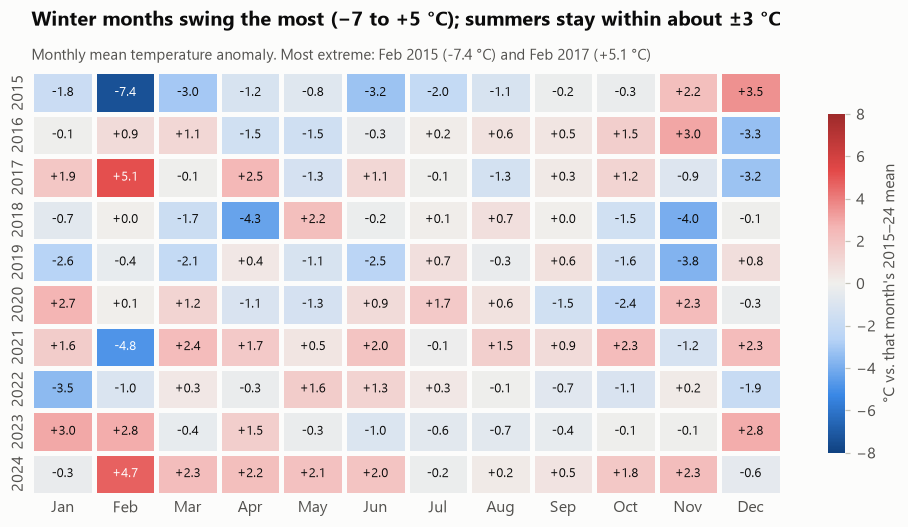

In [11]:
monthly = df.groupby(["year", "month"])["tmean_c"].mean().unstack()
monthly_anom = monthly - monthly.mean()
lim = np.ceil(monthly_anom.abs().max().max())

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(monthly_anom, cmap=DIVERGING, norm=TwoSlopeNorm(0, -lim, lim), annot=True, fmt="+.1f",
            annot_kws={"fontsize": 8.5}, linewidths=2, linecolor=SURFACE,
            cbar_kws={"label": "°C vs. that month's 2015–24 mean", "shrink": 0.8}, ax=ax)
for t in ax.texts:  # keep labels legible on dark cells
    t.set_color("#ffffff" if abs(float(t.get_text())) > lim * 0.55 else INK)
ax.set_xticklabels(MONTHS, rotation=0)
ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(length=0)
ax.grid(False)
hot_m = monthly_anom.stack().idxmax(); cold_m = monthly_anom.stack().idxmin()
titled(ax, "Winter months swing the most (−7 to +5 °C); summers stay within about ±3 °C",
       f"Monthly mean temperature anomaly. Most extreme: {MONTHS[cold_m[1]-1]} {cold_m[0]} "
       f"({monthly_anom.loc[cold_m]:+.1f} °C) and {MONTHS[hot_m[1]-1]} {hot_m[0]} ({monthly_anom.loc[hot_m]:+.1f} °C)")
save(fig, "04_monthly_anomaly_heatmap")

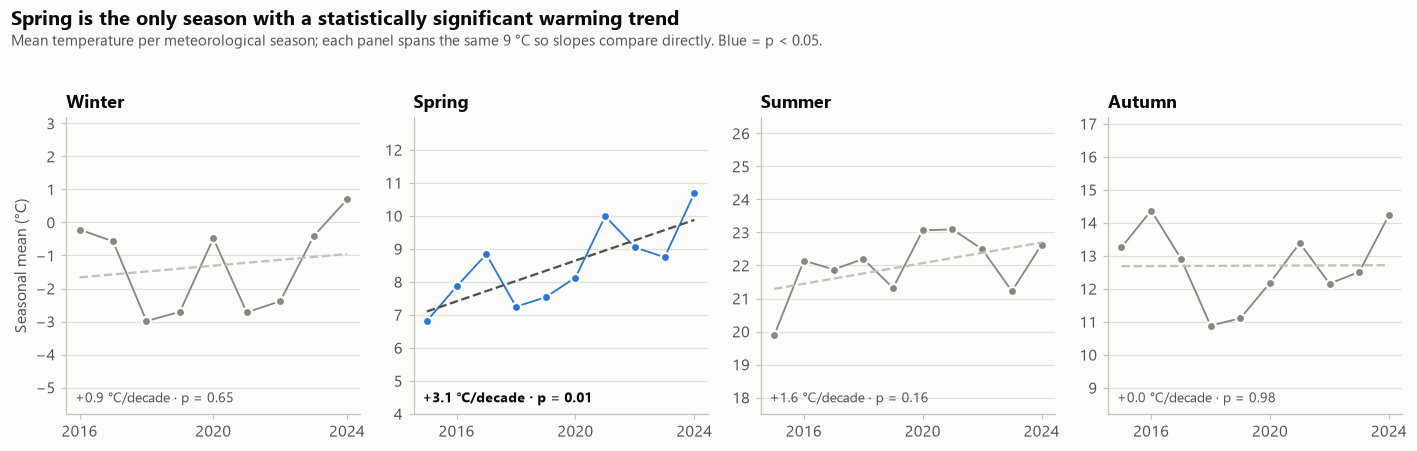

,slope_per_decade,r2,p_ols,p_kendall
Winter,0.88,0.03,0.65,0.48
Spring,3.08,0.59,0.01,0.02
Summer,1.56,0.23,0.16,0.22
Autumn,0.03,0.00,0.98,1.00


In [12]:
# Only complete seasons: drops winter 2015 (no Dec 2014) and winter 2025 (only Dec 2024).
days = df.groupby(["season", "season_year"]).size()
complete = days[days >= 88].index
seasonal = (df.set_index(["season", "season_year"]).loc[lambda d: d.index.isin(complete)]
              .groupby(level=[0, 1])["tmean_c"].mean())
order = ["Winter", "Spring", "Summer", "Autumn"]
season_trends = pd.DataFrame({s: trend(seasonal.loc[s]) for s in order}).T

fig, axes = plt.subplots(1, 4, figsize=(13, 3.8))
for ax, s in zip(axes, order):
    ser, t = seasonal.loc[s], season_trends.loc[s]
    sig = t["p_ols"] < 0.05
    ax.plot(ser.index, ser, color=BLUE if sig else MUTED, marker="o", ms=6, lw=1.2,
            markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax.plot(ser.index, t["intercept"] + t["slope_per_year"] * ser.index, color=INK_2 if sig else AXIS,
            ls="--", lw=1.5)
    mid = ser.mean()
    ax.set_ylim(mid - 4.5, mid + 4.5)  # identical 9 °C span in every panel -> slopes are comparable
    ax.set_title(s, fontsize=11.5, pad=6)
    ax.text(0.03, 0.04, f"{t['slope_per_decade']:+.1f} °C/decade · p = {t['p_ols']:.2f}",
            transform=ax.transAxes, fontsize=9, color=INK if sig else INK_2,
            fontweight="bold" if sig else "normal")
    ax.set_xticks([2016, 2020, 2024])
axes[0].set_ylabel("Seasonal mean (°C)")
fig.suptitle("Spring is the only season with a statistically significant warming trend",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK, y=1.07)
fig.text(0.01, 0.985, "Mean temperature per meteorological season; each panel spans the same 9 °C so slopes compare directly. "
         "Blue = p < 0.05.", color=INK_2, fontsize=10)
fig.tight_layout()
save(fig, "05_seasonal_trends")
season_trends[["slope_per_decade", "r2", "p_ols", "p_kendall"]]

**Seasonality.** Chicago has a strongly continental climate: average highs near 0 °C in January and 27 °C in July, and **winter variability is about twice summer's** (standard deviation of the daily anomaly: 5.9 °C in winter vs. 3.0 °C in summer). Spring is the only season with a significant trend (+3.1 °C/decade, p = 0.01). Summer leans warmer (+1.6 °C/decade) but is not significant. Winter shows almost no trend (+0.9 °C/decade, p = 0.65) because bitter winters (2018, 2019, 2021) and mild ones (2016, 2020, 2024) alternate. Autumn is flat.

## 5. Q3: Extremes

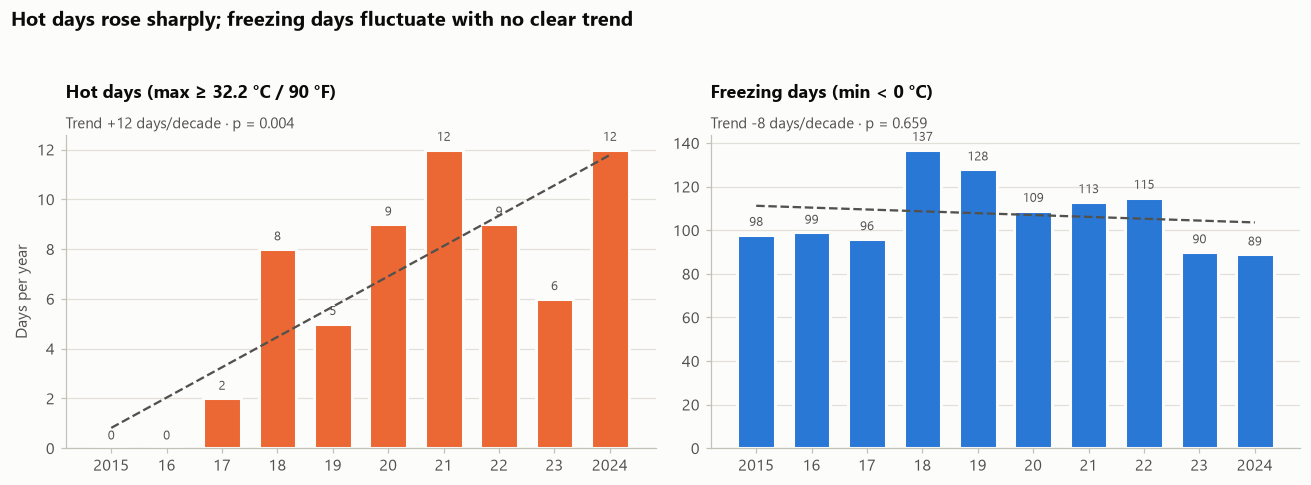

In [13]:
t_hot, t_frz = trend(annual["hot_days"]), trend(annual["freezing_days"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col, color, t, label in [
        (axes[0], "hot_days", ORANGE, t_hot, "Hot days (max ≥ 32.2 °C / 90 °F)"),
        (axes[1], "freezing_days", BLUE, t_frz, "Freezing days (min < 0 °C)")]:
    ax.bar(annual.index, annual[col], color=color, width=0.68, edgecolor=SURFACE, linewidth=2)
    ax.plot(annual.index, t["intercept"] + t["slope_per_year"] * annual.index, color=INK_2, ls="--", lw=1.5)
    for yr, v in annual[col].items():
        ax.text(yr, v + annual[col].max() * 0.02, f"{v:.0f}", ha="center", va="bottom", fontsize=8.5, color=INK_2)
    ax.set_xticks(annual.index, [str(y)[2:] if y not in (2015, 2024) else str(y) for y in annual.index])
    ax.set_title(label, fontsize=11.5, pad=24)
    ax.text(0, 1.02, f"Trend {t['slope_per_decade']:+.0f} days/decade · p = {t['p_ols']:.3f}",
            transform=ax.transAxes, color=INK_2, fontsize=9.5)
axes[0].set_ylabel("Days per year")
fig.suptitle("Hot days rose sharply; freezing days fluctuate with no clear trend",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK, y=1.04)
fig.tight_layout()
save(fig, "06_hot_and_freezing_days")

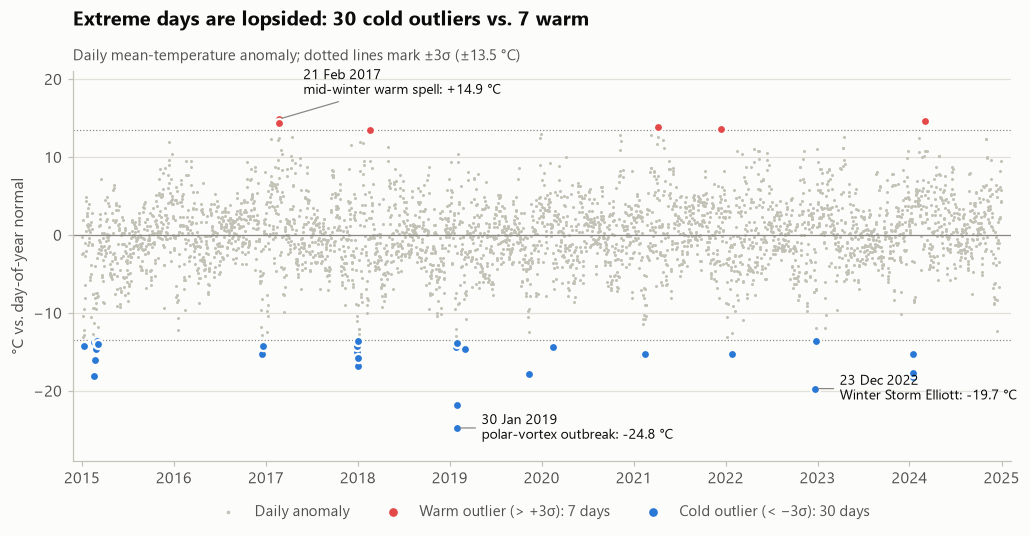

In [14]:
out = df[df["is_temp_outlier"]]
thr = 3 * df["tmean_anomaly_c"].std()
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.scatter(df["date"], df["tmean_anomaly_c"], s=4, color=AXIS, lw=0, label="Daily anomaly")
for sign, color, lab in [(1, RED, "Warm outlier (> +3σ)"), (-1, BLUE, "Cold outlier (< −3σ)")]:
    o = out[np.sign(out["tmean_anomaly_c"]) == sign]
    ax.scatter(o["date"], o["tmean_anomaly_c"], s=36, color=color, edgecolor=SURFACE, lw=1.5, zorder=3,
               label=f"{lab}: {len(o)} days")
for y in (thr, -thr):
    ax.axhline(y, color=MUTED, lw=0.8, ls=":")
ax.axhline(0, color=MUTED, lw=0.8)
events = {"2019-01-30": "30 Jan 2019\npolar-vortex outbreak", "2022-12-23": "23 Dec 2022\nWinter Storm Elliott",
          "2017-02-21": "21 Feb 2017\nmid-winter warm spell"}
for d, text in events.items():
    r = df.loc[df["date"] == d].iloc[0]
    ax.annotate(f"{text}: {r['tmean_anomaly_c']:+.1f} °C", (r["date"], r["tmean_anomaly_c"]),
                xytext=(16, 14 if r["tmean_anomaly_c"] > 0 else 0), textcoords="offset points", fontsize=9,
                color=INK, va="bottom" if r["tmean_anomaly_c"] > 0 else "center", arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set_ylim(-29, 21)
ax.set_ylabel("°C vs. day-of-year normal")
ax.legend(loc="upper center", ncol=3, fontsize=9.5, bbox_to_anchor=(0.5, -0.08), markerscale=1.2)
ax.margins(x=0.01)
titled(ax, f"Extreme days are lopsided: {(out['tmean_anomaly_c'] < 0).sum()} cold outliers vs. "
           f"{(out['tmean_anomaly_c'] > 0).sum()} warm",
       f"Daily mean-temperature anomaly; dotted lines mark ±3σ (±{thr:.1f} °C)")
save(fig, "07_temperature_anomaly_outliers")

In [15]:
records = pd.DataFrame({
    "Hottest days": df.nlargest(5, "tmax_c")[["date", "tmax_c"]].apply(lambda r: f"{r.date:%d %b %Y} · {r.tmax_c:.1f} °C", axis=1).values,
    "Coldest nights": df.nsmallest(5, "tmin_c")[["date", "tmin_c"]].apply(lambda r: f"{r.date:%d %b %Y} · {r.tmin_c:.1f} °C", axis=1).values,
    "Wettest days": df.nlargest(5, "precip_mm")[["date", "precip_mm"]].apply(lambda r: f"{r.date:%d %b %Y} · {r.precip_mm:.1f} mm", axis=1).values,
    "Snowiest days": df.nlargest(5, "snow_cm")[["date", "snow_cm"]].apply(lambda r: f"{r.date:%d %b %Y} · {r.snow_cm:.1f} cm", axis=1).values,
}, index=range(1, 6))
records

,Hottest days,Coldest nights,Wettest days,Snowiest days
1,21 Jun 2022 · 37.4 °C,31 Jan 2019 · -32.5 °C,02 Jul 2023 · 137.8 mm,01 Feb 2015 · 18.7 cm
2,24 Aug 2023 · 37.1 °C,30 Jan 2019 · -30.8 °C,21 Jun 2018 · 76.2 mm,27 Apr 2019 · 13.2 cm
3,23 Aug 2023 · 36.6 °C,15 Jan 2024 · -25.0 °C,15 Jul 2020 · 64.7 mm,21 Nov 2015 · 12.9 cm
4,27 Aug 2024 · 36.2 °C,26 Jan 2022 · -24.5 °C,17 May 2020 · 60.5 mm,14 Apr 2019 · 12.2 cm
5,14 Jun 2022 · 35.9 °C,26 Jan 2019 · -24.4 °C,14 Oct 2017 · 52.9 mm,26 Nov 2018 · 12.2 cm


**Extremes.** Hot days are the clearest trend in the whole dataset. Extreme anomalies, by contrast, are **mostly cold**: Arctic outbreaks such as the January 2019 polar vortex (daily mean −28.3 °C, overnight low −32.5 °C) sit far further below normal than any warm spell sits above it. All seven warm outliers fall between December and April, so in Chicago an "extremely warm" day relative to normal is a mild winter day, not a summer heatwave. Summer heat is high in absolute terms but stays close to the seasonal norm.

## 6. Q4: Precipitation

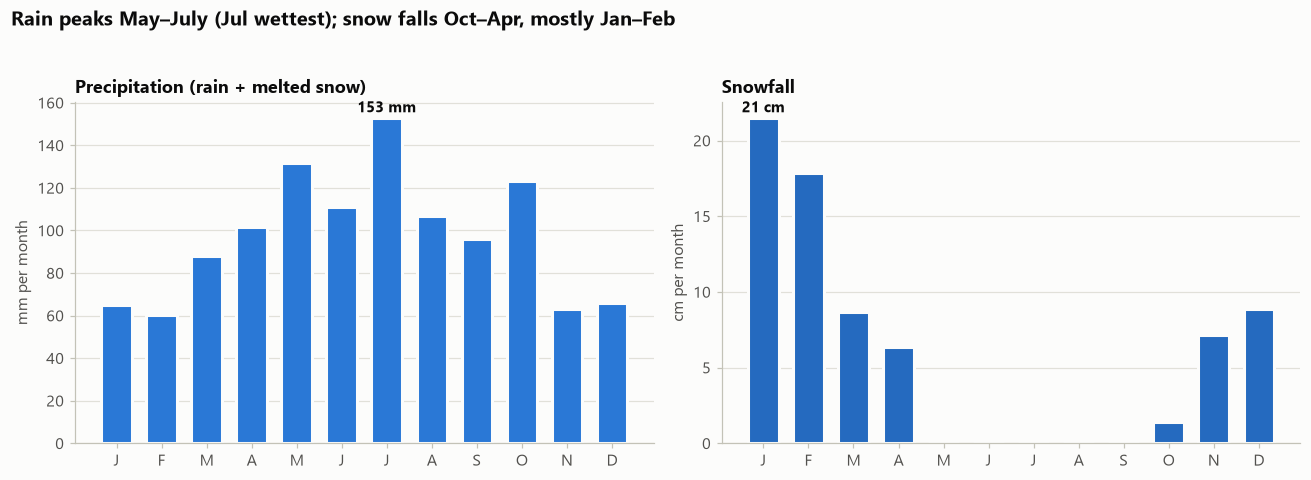

In [16]:
n_years = df["year"].nunique()
mon = df.groupby("month").agg(precip=("precip_mm", "sum"), snow=("snow_cm", "sum"), wet=("is_wet_day", "sum")) / n_years

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1]})
axes[0].bar(x, mon["precip"], color=BLUE, width=0.68, edgecolor=SURFACE, linewidth=2)
axes[0].set_xticks(x, [m[0] for m in MONTHS])
axes[0].set_ylabel("mm per month")
axes[0].set_title("Precipitation (rain + melted snow)", fontsize=11.5, pad=6)
wettest = mon["precip"].idxmax()
axes[0].annotate(f"{mon['precip'].max():.0f} mm", (wettest - 1, mon["precip"].max()), xytext=(0, 4),
                 textcoords="offset points", ha="center", fontsize=9.5, color=INK, fontweight="bold")
axes[1].bar(x, mon["snow"], color="#256abf", width=0.68, edgecolor=SURFACE, linewidth=2)
axes[1].set_xticks(x, [m[0] for m in MONTHS])
axes[1].set_ylabel("cm per month")
axes[1].set_title("Snowfall", fontsize=11.5, pad=6)
axes[1].annotate(f"{mon['snow'].max():.0f} cm", (mon["snow"].idxmax() - 1, mon["snow"].max()), xytext=(0, 4),
                 textcoords="offset points", ha="center", fontsize=9.5, color=INK, fontweight="bold")
fig.suptitle(f"Rain peaks May–July ({MONTHS[wettest-1]} wettest); snow falls Oct–Apr, mostly Jan–Feb",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK, y=1.03)
fig.tight_layout()
save(fig, "08_monthly_precipitation_snow")

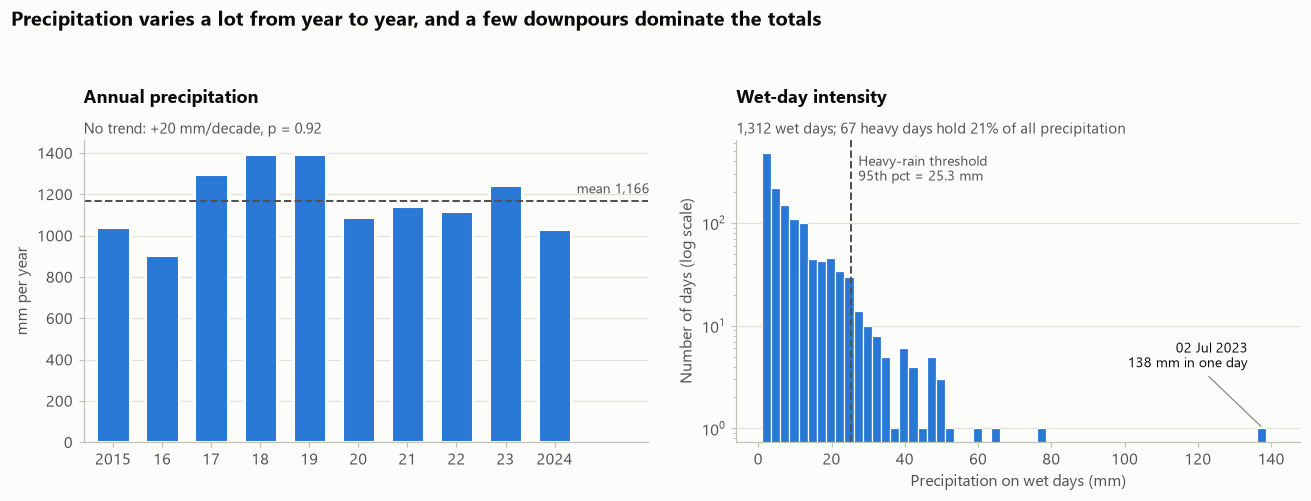

In [17]:
wet = df.loc[df["is_wet_day"], "precip_mm"]
p95 = quality["heavy_precip_threshold_mm"]
heavy = df[df["is_heavy_precip_day"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
ax.bar(annual.index, annual["precip_mm"], color=BLUE, width=0.68, edgecolor=SURFACE, linewidth=2)
ax.axhline(annual["precip_mm"].mean(), color=INK_2, ls="--", lw=1.3)
ax.text(annual.index[-1] + 0.45, annual["precip_mm"].mean() + 25, f"mean {annual['precip_mm'].mean():,.0f}",
        color=INK_2, fontsize=9, va="bottom")
ax.set_xticks(annual.index, [str(y)[2:] if y not in (2015, 2024) else str(y) for y in annual.index])
ax.set_ylabel("mm per year")
ax.set_xlim(2014.4, 2025.9)
ax.set_title("Annual precipitation", fontsize=11.5, pad=24)
ax.text(0, 1.02, f"No trend: {trends.loc['Total precipitation (mm)', 'slope_per_decade']:+.0f} mm/decade, "
        f"p = {trends.loc['Total precipitation (mm)', 'p_ols']:.2f}", transform=ax.transAxes, color=INK_2, fontsize=9.5)

ax = axes[1]
bins = np.arange(1, wet.max() + 5, 2.5)
ax.hist(wet, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.8)
ax.set_yscale("log")
ax.axvline(p95, color=INK_2, ls="--", lw=1.3)
ax.text(p95 + 2, ax.get_ylim()[1] * 0.4, f"Heavy-rain threshold\n95th pct = {p95:.1f} mm", color=INK_2, fontsize=9)
top = df.loc[df["precip_mm"].idxmax()]
ax.annotate(f"{top['date']:%d %b %Y}\n{top['precip_mm']:.0f} mm in one day", (top["precip_mm"], 1),
            xytext=(-10, 40), textcoords="offset points", ha="right", fontsize=9, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set_xlabel("Precipitation on wet days (mm)")
ax.set_ylabel("Number of days (log scale)")
ax.grid(axis="y", which="minor", visible=False)
ax.set_title("Wet-day intensity", fontsize=11.5, pad=24)
ax.text(0, 1.02, f"{len(wet):,} wet days; {len(heavy)} heavy days hold "
        f"{heavy['precip_mm'].sum() / df['precip_mm'].sum():.0%} of all precipitation",
        transform=ax.transAxes, color=INK_2, fontsize=9.5)
fig.suptitle("Precipitation varies a lot from year to year, and a few downpours dominate the totals",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK, y=1.05)
fig.tight_layout()
save(fig, "09_annual_precip_and_intensity")

**Precipitation.** Annual totals range from ~900 mm (2016) to ~1,395 mm (2018–2019) with **no trend**. Rain concentrates from May to July, and snow falls mainly from December to February (about 20 cm/month in January). The distribution is very skewed: 36 % of days are wet, but the wettest 5 % of wet days (under 2 % of all days) deliver about a fifth (21 %) of all precipitation. The single largest event, **2 July 2023 (138 mm)**, matches the record-setting flash flooding on Chicago's West Side that day.

*Note:* ERA5 is a ~25 km gridded reanalysis, so it smooths local convective storms. Point gauges recorded higher totals in some neighbourhoods on 2 July 2023.

## 7. Q5: How weather variables relate

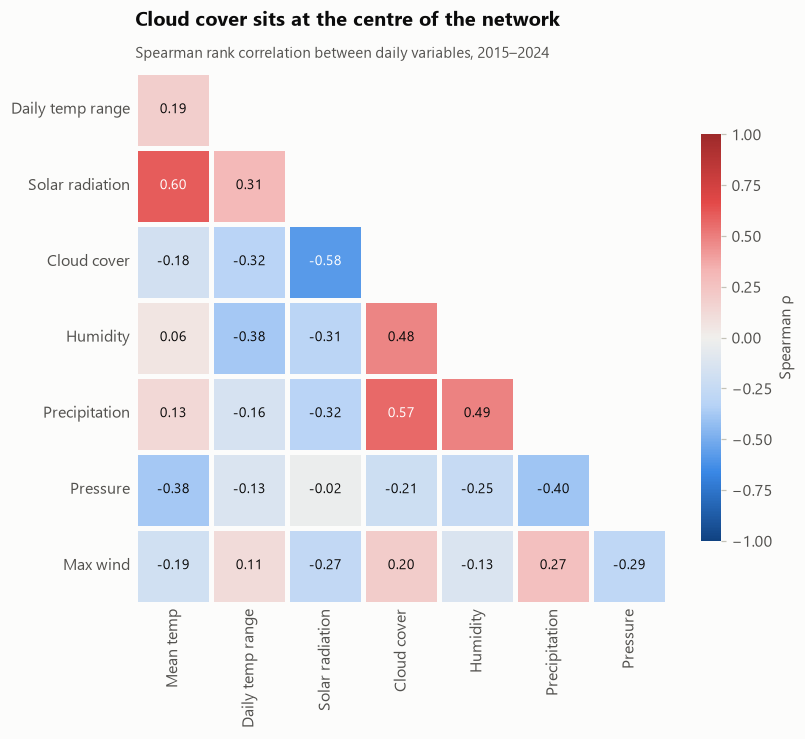

In [18]:
corr_cols = {"tmean_c": "Mean temp", "temp_range_c": "Daily temp range", "solar_mj_m2": "Solar radiation",
             "cloud_pct": "Cloud cover", "humidity_pct": "Humidity", "precip_mm": "Precipitation",
             "pressure_hpa": "Pressure", "wind_max_kmh": "Max wind"}
corr = df[list(corr_cols)].rename(columns=corr_cols).corr(method="spearman")
corr = corr.iloc[1:, :-1]  # drop the empty first row / last column of the lower triangle
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7.8, 6.4))
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"fontsize": 9},
            linewidths=2, linecolor=SURFACE, square=True, cbar_kws={"label": "Spearman ρ", "shrink": 0.75}, ax=ax)
for t in ax.texts:
    t.set_color("#ffffff" if abs(float(t.get_text())) > 0.55 else INK)
ax.tick_params(length=0); ax.grid(False)
titled(ax, "Cloud cover sits at the centre of the network",
       "Spearman rank correlation between daily variables, 2015–2024")
save(fig, "10_correlation_matrix")

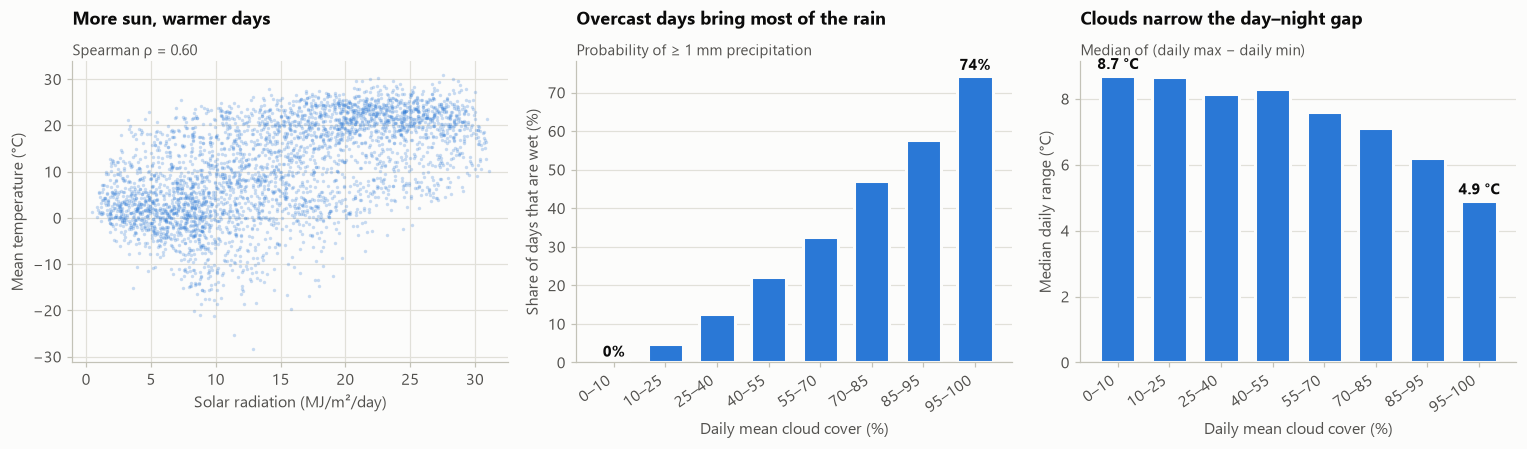

,share_wet,median_temp_range_c,days
cloud_bin,,,
0–10,0.00,8.70,255
10–25,0.05,8.65,360
25–40,0.12,8.15,408
40–55,0.22,8.30,483
55–70,0.33,7.60,515
70–85,0.47,7.10,604
85–95,0.58,6.20,474
95–100,0.74,4.90,554


In [19]:
df["cloud_bin"] = pd.cut(df["cloud_pct"], bins=[-0.1, 10, 25, 40, 55, 70, 85, 95, 100],
                         labels=["0–10", "10–25", "25–40", "40–55", "55–70", "70–85", "85–95", "95–100"])
by_cloud = df.groupby("cloud_bin", observed=True).agg(wet_share=("is_wet_day", "mean"),
                                                      dtr=("temp_range_c", "median"), n=("date", "size"))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
ax = axes[0]
ax.scatter(df["solar_mj_m2"], df["tmean_c"], s=5, color=BLUE, alpha=0.25, lw=0)
r = stats.spearmanr(df["solar_mj_m2"], df["tmean_c"]).statistic
ax.set_xlabel("Solar radiation (MJ/m²/day)"); ax.set_ylabel("Mean temperature (°C)")
ax.set_title("More sun, warmer days", fontsize=11.5, pad=24)
ax.text(0, 1.02, f"Spearman ρ = {r:.2f}", transform=ax.transAxes, color=INK_2, fontsize=9.5)
ax.grid(axis="x")

xb = np.arange(len(by_cloud))
ax = axes[1]
ax.bar(xb, by_cloud["wet_share"] * 100, color=BLUE, width=0.68, edgecolor=SURFACE, linewidth=2)
for i, v in enumerate(by_cloud["wet_share"] * 100):
    if i in (0, len(xb) - 1):
        ax.text(i, v + 1.5, f"{v:.0f}%", ha="center", fontsize=9.5, color=INK, fontweight="bold")
ax.set_xticks(xb, by_cloud.index, rotation=35, ha="right")
ax.set_xlabel("Daily mean cloud cover (%)"); ax.set_ylabel("Share of days that are wet (%)")
ax.set_title("Overcast days bring most of the rain", fontsize=11.5, pad=24)
ax.text(0, 1.02, "Probability of ≥ 1 mm precipitation", transform=ax.transAxes, color=INK_2, fontsize=9.5)

ax = axes[2]
ax.bar(xb, by_cloud["dtr"], color=BLUE, width=0.68, edgecolor=SURFACE, linewidth=2)
for i, v in enumerate(by_cloud["dtr"]):
    if i in (0, len(xb) - 1):
        ax.text(i, v + 0.2, f"{v:.1f} °C", ha="center", fontsize=9.5, color=INK, fontweight="bold")
ax.set_xticks(xb, by_cloud.index, rotation=35, ha="right")
ax.set_xlabel("Daily mean cloud cover (%)"); ax.set_ylabel("Median daily range (°C)")
ax.set_title("Clouds narrow the day–night gap", fontsize=11.5, pad=24)
ax.text(0, 1.02, "Median of (daily max − daily min)", transform=ax.transAxes, color=INK_2, fontsize=9.5)
fig.tight_layout()
save(fig, "11_variable_relationships")
by_cloud.rename(columns={"wet_share": "share_wet", "dtr": "median_temp_range_c", "n": "days"})

**Relationships.** *Solar radiation* is the strongest driver of temperature (ρ ≈ 0.60), mostly through the seasonal cycle. *Cloud cover* links most of the other variables: overcast days are far more likely to be wet, have less sun, and show a much smaller day–night temperature range, because clouds block daytime sunshine and hold heat in overnight. *Low pressure* goes with precipitation (ρ ≈ −0.40) and stronger wind, the signature of passing storm systems.

*Caveat:* correlations on raw daily values include the shared seasonal cycle (summer is warm, sunny **and** humid). They describe co-occurrence, not causation.

## 8. Key findings

In [20]:
key = {
    "Decade mean temperature": f"{df['tmean_c'].mean():.1f} °C",
    "Annual-mean trend": f"{t_mean['slope_per_decade']:+.1f} °C/decade (p_OLS = {t_mean['p_ols']:.3f}, p_Kendall = {t_mean['p_kendall']:.3f})",
    "Warmest / coolest year": f"{annual['mean_temp_c'].idxmax()} ({annual['mean_temp_c'].max():.1f} °C) / {annual['mean_temp_c'].idxmin()} ({annual['mean_temp_c'].min():.1f} °C)",
    "Hot days ≥ 32.2 °C trend": f"{t_hot['slope_per_decade']:+.1f} days/decade (p = {t_hot['p_ols']:.3f}, R² = {t_hot['r2']:.2f})",
    "Spring trend": f"{season_trends.loc['Spring', 'slope_per_decade']:+.1f} °C/decade (p = {season_trends.loc['Spring', 'p_ols']:.3f})",
    "Record high / low": f"{df['tmax_c'].max():.1f} °C ({df.loc[df['tmax_c'].idxmax(), 'date']:%d %b %Y}) / {df['tmin_c'].min():.1f} °C ({df.loc[df['tmin_c'].idxmin(), 'date']:%d %b %Y})",
    "Mean annual precipitation": f"{annual['precip_mm'].mean():,.0f} mm (no significant trend)",
    "Wettest day": f"{top['precip_mm']:.1f} mm on {top['date']:%d %b %Y}",
    "Share of precip from heavy days": f"{heavy['precip_mm'].sum() / df['precip_mm'].sum():.0%} from {len(heavy) / len(df):.1%} of days",
    "Temperature outliers (±3σ)": f"{len(out)} days: {(out['tmean_anomaly_c'] < 0).sum()} cold, {(out['tmean_anomaly_c'] > 0).sum()} warm",
}
pd.Series(key, name="").to_frame()

,
Decade mean temperature,10.4 °C
Annual-mean trend,"+1.7 °C/decade (p_OLS = 0.050, p_Kendall = 0.047)"
Warmest / coolest year,2024 (11.8 °C) / 2015 (9.2 °C)
Hot days ≥ 32.2 °C trend,"+12.2 days/decade (p = 0.004, R² = 0.67)"
Spring trend,+3.1 °C/decade (p = 0.010)
Record high / low,37.4 °C (21 Jun 2022) / -32.5 °C (31 Jan 2019)
Mean annual precipitation,"1,166 mm (no significant trend)"
Wettest day,137.8 mm on 02 Jul 2023
Share of precip from heavy days,21% from 1.8% of days
Temperature outliers (±3σ),"37 days: 30 cold, 7 warm"


1. **Warming signal, short record.** The decade's annual mean rose by roughly 1.7 °C/decade (borderline significant, p ≈ 0.05), and 2024 was the warmest year. The slope is inflated by natural variability over only ten points.
2. **Hot days are the strongest trend.** Days ≥ 32.2 °C went from 0 per year (2015–16) to 12 (2021, 2024), a statistically robust increase (p < 0.01).
3. **Spring is the only season with a significant trend** (+3.1 °C/decade, p = 0.01). Winter barely trends (+0.9 °C/decade) because of its huge year-to-year swings.
4. **Cold extremes are larger than warm ones.** 30 of 37 ±3σ days were cold outbreaks, led by the January 2019 polar vortex (−32.5 °C). Warm outliers happen in winter, not summer.
5. **Precipitation has no trend but is concentrated.** About 1,166 mm/yr, peaking May–July. The heaviest 5 % of wet days supply 21 % of the total, and the 2 July 2023 deluge (138 mm) is the decade's largest day.
6. **Cloud cover ties the system together.** It raises the chance of rain, blocks sun and compresses the daily temperature range.

### Limitations
- **Reanalysis, not a station.** ERA5 is modelled on a ~25 km grid. It is consistent and gap-free, but it underestimates local extremes (especially convective rain) compared with O'Hare or Midway gauges.
- **Ten years is weather-scale.** Trends are descriptive and sensitive to the start and end years. Robust climate trends need ≥ 30 years.
- **Baseline is internal.** Anomalies are relative to 2015–2024 itself, not to the official 1991–2020 climate normals.
- **Correlations ≠ causation**, and they include the shared seasonal cycle.

### Possible extensions
Compare against NOAA station data for O'Hare; extend to 1950–2024 for a climate-scale trend; deseasonalise before correlating; add a simple forecasting model (SARIMA / Prophet) for monthly temperature.